In [1]:
import torch
import torch.optim
import torch.nn as nn
import torch.nn.functional as F

In [2]:
import numpy as np

In [3]:
from lstm import BaselineLSTM

In [4]:
device = torch.device("cuda")

In [5]:
loss_fn = nn.CrossEntropyLoss()

In [6]:
from dataset import WindowDataset, LOBSTERLevel10Dataset
from torch.utils.data import DataLoader

In [7]:
dataset = WindowDataset(LOBSTERLevel10Dataset(train=True), window_size=30)
data_loader = DataLoader(dataset, shuffle=True, batch_size=64)

/home/carson/projects/PatternAnalysis-2026/recognition/dataset.py:94: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  self.data = torch.tensor([midpoints, spreads, *ask_gaps, *bid_gaps]).T


In [8]:
model = BaselineLSTM().to(device)

In [9]:
optim = torch.optim.Adam(model.parameters(), lr=3e-4)

In [10]:
for epoch in range(10):
    batch_losses = []
    for i, (window, label) in enumerate(data_loader):
        window, label = window.to(dtype=torch.float32, device=device), label.to(dtype=torch.float32, device=device)
        shifted = torch.concatenate((window[:, 1:, :], torch.reshape(label, (label.shape[0], 1, label.shape[1]))), dim=1)
        optim.zero_grad()
        _, (mu, sigma), _ = model(window)
        loss = F.gaussian_nll_loss(mu, shifted, sigma ** 2)
        loss.backward()
        optim.step()
        batch_losses.append(loss.item())
    print(f"Finished epoch {epoch + 1}: mean batch loss: {np.mean(batch_losses)}")

Finished epoch 1: mean batch loss: -0.033603466292853254
Finished epoch 2: mean batch loss: -0.26594557475983294
Finished epoch 3: mean batch loss: -0.31204132557314535
Finished epoch 4: mean batch loss: -0.485150857682023
Finished epoch 5: mean batch loss: -0.876398270245316
Finished epoch 6: mean batch loss: -1.0968355959072862
Finished epoch 7: mean batch loss: -1.2453626668718616
Finished epoch 8: mean batch loss: -1.405100600525192
Finished epoch 9: mean batch loss: -1.5289544739419694
Finished epoch 10: mean batch loss: -1.5881215503765258


In [11]:
validation_loader = DataLoader(WindowDataset(LOBSTERLevel10Dataset(train=False), window_size=30), batch_size=64)

with torch.no_grad():
    batch_losses = []
    for window, label in validation_loader:
        window, label = window.to(dtype=torch.float32, device=device), label.to(dtype=torch.float32, device=device)
        shifted = torch.concatenate((window[:, 1:, :], torch.reshape(label, (label.shape[0], 1, label.shape[1]))), dim=1)
        _, (mu, sigma), _ = model(window)
        loss = F.gaussian_nll_loss(mu, shifted, sigma ** 2)
        batch_losses.append(loss.item())
    print(f"Mean batch validation loss: {np.mean(batch_losses)}")

Mean batch validation loss: 1.5150775880417624


In [12]:
import pandas as pd

feature_names = ["log_midpoint", "log1p_spread"] + [
    f"log1p_{side}_gap_{level}" for side in ("ask", "bid") for level in range(2, 11)
]
feature_names += [f"log1p_{side}_size_{level}" for level in range(1, 11) for side in ("ask", "bid")]
metrics, was_training = {}, model.training
model.eval()
try:
    with torch.inference_mode():
        for split, loader in (("train", data_loader), ("validation", validation_loader)):
            totals = torch.zeros(4, len(feature_names), dtype=torch.float64, device=device)
            count = 0
            for window, label in loader:
                window, label = (x.to(device=device, dtype=torch.float32) for x in (window, label))
                target = torch.cat((window[:, 1:], label[:, None]), dim=1)
                _, (mu, sigma), _ = model(window)
                squared_error = (mu - target).square()
                nll = F.gaussian_nll_loss(mu, target, sigma.square(), reduction="none")
                scaled_mse = squared_error / sigma.square().clamp_min(1e-6)
                # Weight every timestep equally, including the smaller final batch.
                totals += torch.stack((squared_error, nll, sigma, scaled_mse)).sum((1, 2), dtype=torch.float64)
                count += window.shape[0] * window.shape[1]
            for name, values in zip(("mse", "nll", "sigma", "scaled_mse"), (totals / count).cpu().numpy()):
                metrics[f"{split}_{name}"] = values
finally:
    model.train(was_training)
comparison = pd.DataFrame(metrics, index=feature_names)
comparison["nll_gap"] = comparison["validation_nll"] - comparison["train_nll"]
display(comparison.sort_values("nll_gap", ascending=False))
print("Overall mean NLL:", comparison[["train_nll", "validation_nll"]].mean().to_dict())

,train_mse,train_nll,train_sigma,train_scaled_mse,validation_mse,validation_nll,validation_sigma,validation_scaled_mse,nll_gap
log1p_ask_gap_5,0.061436,-2.323927,0.164077,0.681158,0.039779,7.493990,0.120088,20.535179,9.817917
log1p_ask_gap_4,0.055733,-2.233513,0.130543,1.130642,0.038563,5.062791,0.095867,16.024725,7.296304
log1p_bid_gap_4,0.060701,-1.958017,0.134137,1.318119,0.037470,3.929072,0.103236,13.271666,5.887089
log1p_ask_gap_2,0.061677,-2.015989,0.167739,0.599630,0.051968,3.641488,0.130635,12.132926,5.657477
log1p_ask_gap_6,0.075489,-2.063009,0.191372,0.698271,0.043310,3.339410,0.142162,11.703802,5.402418
log1p_bid_gap_3,0.065874,-1.416113,0.137329,2.252284,0.047078,3.920255,0.119977,12.884940,5.336368
log1p_bid_gap_2,0.068707,-1.751095,0.169379,0.894248,0.047159,1.499860,0.151475,7.369527,3.250955
log1p_bid_gap_8,0.080817,-1.777626,0.171158,1.188882,0.041997,1.353827,0.124522,7.859494,3.131452
log1p_ask_gap_8,0.087822,-1.559772,0.211881,0.955559,0.055975,0.688090,0.174012,5.566383,2.247862
log1p_bid_gap_9,0.079318,-1.607572,0.305003,0.528679,0.047672,0.610817,0.237009,5.353376,2.218388


Overall mean NLL: {'train_nll': -1.501048661997927, 'validation_nll': 1.513329504097039}


In [13]:
from lstm import SplitBaselineLSTM
split_model = SplitBaselineLSTM(torch.diff(data_loader.dataset.data.data[:, 0]).std().item()).to(device)
split_model.load_state_dict(model.state_dict(), strict=False)
split_model._midpoint.requires_grad_(False)
split_optim = torch.optim.Adam(split_model.parameters(), lr=3e-4)
for epoch in range(3):
    for window, label in data_loader:
        window, label = (x.to(device=device, dtype=torch.float32) for x in (window, label))
        split_optim.zero_grad()
        split_model.loss(window, torch.cat((window[:, 1:], label[:, None]), dim=1)).backward()
        split_optim.step()

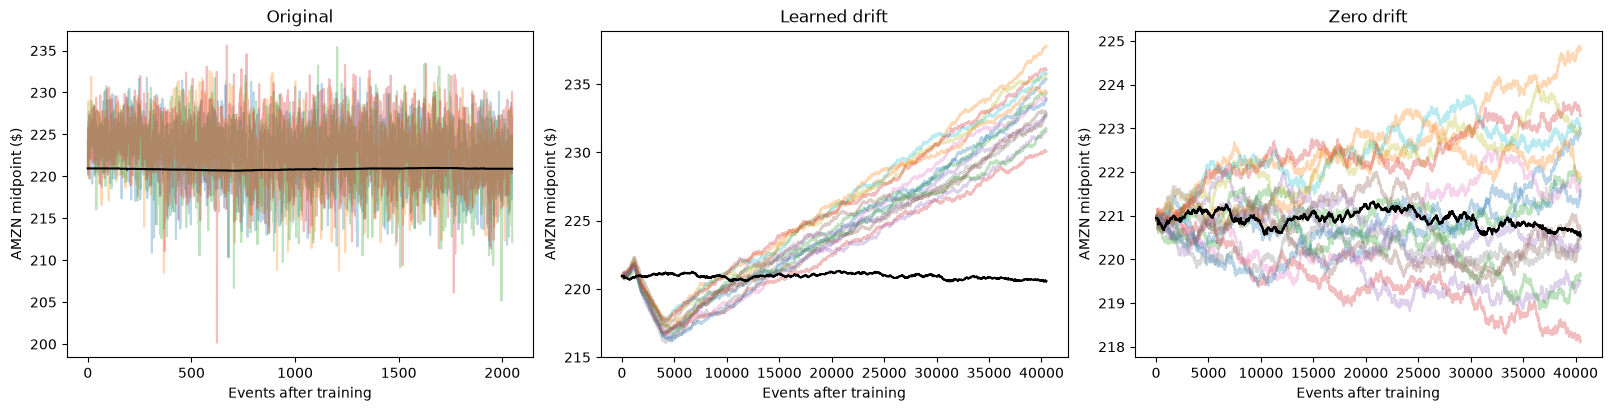

In [20]:
import matplotlib.pyplot as plt
from pathlib import Path
import lstm
runs = Path(lstm.__file__).parent / "runs"
_, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
for ax, (folder, key, title) in zip(axes, [("split_midpoint", "original_log_prices", "Original"), ("split_midpoint_learned_drift", "split_log_prices", "Learned drift"), ("split_midpoint", "split_log_prices", "Zero drift")]):
    saved = np.load(runs / folder / "paths.npz")
    ax.plot(np.exp(saved[key]) / 10000, alpha=0.3)
    ax.plot(np.exp(saved["actual_log_prices"][:len(saved[key])]) / 10000, color="black")
    ax.set(title=title, xlabel="Events after training", ylabel="AMZN midpoint ($)")

In [14]:
from lstm import GaussianReturnLSTM
return_scale = torch.diff(data_loader.dataset.data.data[:, 0]).std().item()
return_windows = (torch.diff(data_loader.dataset.data.data[:, 0]).float().to(device) / return_scale).unfold(0, 31, 1)
return_model = GaussianReturnLSTM().to(device)
nn.init.zeros_(return_model.head.weight)
nn.init.zeros_(return_model.head.bias)
return_optimizer = torch.optim.AdamW(return_model.parameters(), lr=3e-4, weight_decay=1e-4)
for epoch in range(5):
    for indices in torch.randperm(len(return_windows), device=device).split(512):
        batch = return_windows[indices]
        mu, sigma, _ = return_model(batch[:, :30, None])
        loss = F.gaussian_nll_loss(mu, batch[:, 30, None], sigma.square())
        return_optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(return_model.parameters(), 1.0)
        return_optimizer.step()
    print(f"Epoch {epoch + 1}: final batch NLL {loss.item():.4f}")

Epoch 1: final batch NLL 0.2473
Epoch 2: final batch NLL -0.0410
Epoch 3: final batch NLL 0.0057
Epoch 4: final batch NLL 0.2864
Epoch 5: final batch NLL 0.4180


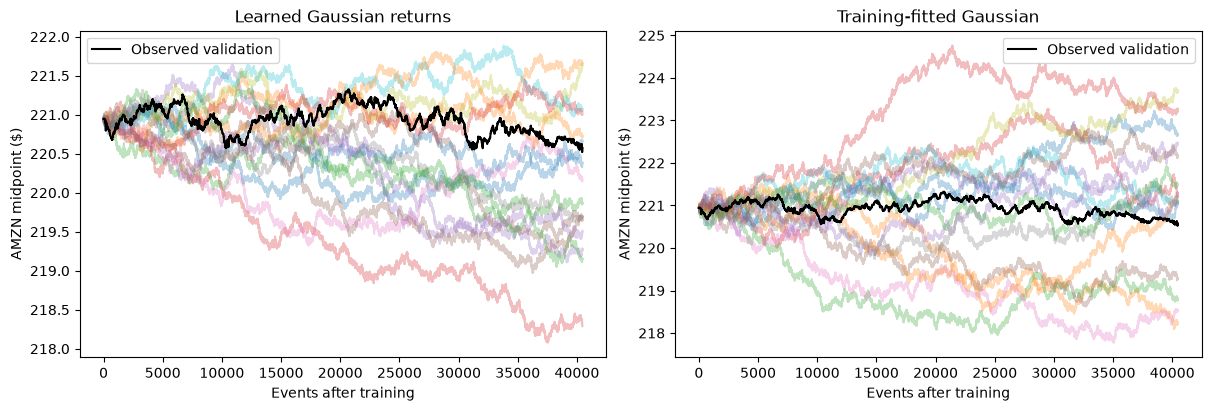

In [20]:
train_log = data_loader.dataset.data.data[:, 0]
observed = np.r_[float(train_log[-1]), validation_loader.dataset.data.data[:, 0].numpy()]
generated = torch.full((len(observed), 16), float(train_log[-1]), dtype=torch.float64, device=device)
with torch.inference_mode(), torch.random.fork_rng(devices=[device]):
    torch.manual_seed(20261025)
    history = (torch.diff(train_log[-31:]) / return_scale).float().to(device)
    mu, sigma, state = return_model(history[None, :, None].repeat(16, 1, 1))
    for step in range(len(observed) - 1):
        draw = mu + sigma * torch.randn_like(mu)
        generated[step + 1] = generated[step] + return_scale * draw[:, 0].double()
        mu, sigma, state = return_model(draw[:, None], state)
increments = np.random.default_rng(20261025).normal(train_log.diff().mean().item(), return_scale, (len(observed) - 1, 16))
reference = observed[0] + np.vstack((np.zeros((1, 16)), increments.cumsum(axis=0)))
_, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, values, title in zip(axes, (generated.cpu().numpy(), reference), ("Learned Gaussian returns", "Training-fitted Gaussian")):
    ax.plot(np.exp(values) / 10000, alpha=0.3)
    ax.plot(np.exp(observed) / 10000, color="black", label="Observed validation")
    ax.set(title=title, xlabel="Events after training", ylabel="AMZN midpoint ($)")
    ax.legend()
plt.show()

In [15]:
import matplotlib.pyplot as plt
import numpy as np

In [16]:
from dataset import LOBSTERLevel10Dataset

train = LOBSTERLevel10Dataset(train=True).data[:, 0].numpy()
validation = LOBSTERLevel10Dataset(train=False).data[:, 0].numpy()

x_train = np.arange(len(train))
x_validation = np.arange(len(validation)) + len(train)

In [17]:
from itertools import islice

In [18]:
with torch.no_grad():
    h, c = torch.zeros(3, 1, 1024).to(device=device, dtype=torch.float32), torch.zeros(3, 1, 1024).to(device=device, dtype=torch.float32)
    for datum in LOBSTERLevel10Dataset(train=True):
        datum = torch.reshape(datum.to(dtype=torch.float32, device=device), (1, 1, datum.shape[0]))
        x, _, (h, c) = model(datum, hx=(h, c))

In [19]:
pred_midpoints = []

with torch.no_grad():
    for _ in validation:
        x, (mean, _), (h, c) = model(x, hx=(h, c))
        pred_midpoints.append((x[0, 0, 0].cpu().item()))

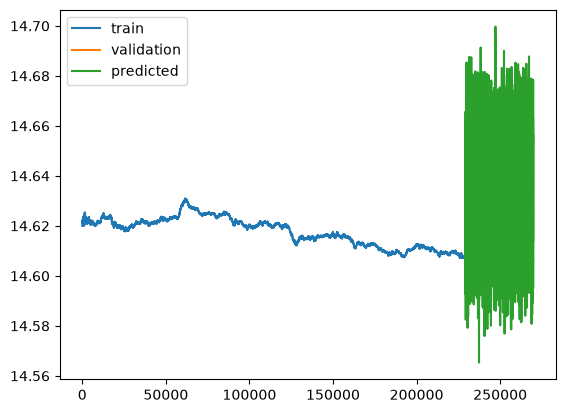

In [20]:
plt.plot(x_train, train, label="train")
plt.plot(x_validation, validation, label="validation")
plt.plot(x_validation, pred_midpoints, label="predicted")
plt.legend()